# Análise de Dados de Clientes com Python — AdventureWorks

**Objetivo:** analisar as vendas de uma loja de bicicletas (AdventureWorks) para entender o comportamento dos clientes e quais fatores estão ligados à **perda de clientes**.

**Ferramentas:** Python, Pandas, Matplotlib e Seaborn.

**Etapas:** 1) Importar os dados · 2) Limpar · 3) Juntar as tabelas · 4) Explorar · 5) Clientes perdidos · 6) Conclusões

> **O que é "cliente perdido" aqui?** A planilha não tem uma coluna de cancelamento. Então considerei *perdido* o cliente que **não compra há mais de 180 dias** (contando até a última data da base).

## 1. Importar os dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mostrar números sem notação científica
pd.options.display.float_format = "{:,.0f}".format

# O arquivo precisa estar na mesma pasta do notebook
arquivo = "AdventureWorks_Sales.xlsx"

vendas = pd.read_excel(arquivo, sheet_name="Sales_data")
pedidos = pd.read_excel(arquivo, sheet_name="Sales Order_data")
produtos = pd.read_excel(arquivo, sheet_name="Product_data")
clientes = pd.read_excel(arquivo, sheet_name="Customer_data")
territorios = pd.read_excel(arquivo, sheet_name="Sales Territory_data")

vendas.head()

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,ShipDateKey,SalesTerritoryKey,Order Quantity,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount
0,43659001,676,-1,349,20170702,20170712,"20,170,709",5,1,"2,025","2,025",0,"1,898","1,898","2,025"
1,43659002,676,-1,350,20170702,20170712,"20,170,709",5,3,"2,025","6,075",0,"1,898","5,694","6,075"
2,43659003,676,-1,351,20170702,20170712,"20,170,709",5,1,"2,025","2,025",0,"1,898","1,898","2,025"
3,43659004,676,-1,344,20170702,20170712,"20,170,709",5,1,"2,040","2,040",0,"1,912","1,912","2,040"
4,43659005,676,-1,345,20170702,20170712,"20,170,709",5,1,"2,040","2,040",0,"1,912","1,912","2,040"


## 2. Limpeza dos dados

In [2]:
# Tem valores vazios? Tem linhas repetidas?
print("Valores vazios por coluna:")
print(vendas.isnull().sum())
print()
print("Linhas repetidas:", vendas.duplicated().sum())

Valores vazios por coluna:
SalesOrderLineKey             0
ResellerKey                   0
CustomerKey                   0
ProductKey                    0
OrderDateKey                  0
DueDateKey                    0
ShipDateKey                2113
SalesTerritoryKey             0
Order Quantity                0
Unit Price                    0
Extended Amount               0
Unit Price Discount Pct       0
Product Standard Cost         0
Total Product Cost            0
Sales Amount                  0
dtype: int64

Linhas repetidas: 0


Só a coluna `ShipDateKey` (data de envio) tem valores vazios: são pedidos que ainda não foram enviados. Não vamos usar essa coluna, então não precisa corrigir. Também não há linhas repetidas.

Agora vamos transformar a data do pedido (que está como número, tipo `20170702`) em data de verdade.

In [3]:
vendas["Data"] = pd.to_datetime(vendas["OrderDateKey"].astype(str), format="%Y%m%d")
vendas["Ano"] = vendas["Data"].dt.year

print("A base vai de", vendas["Data"].min().date(), "até", vendas["Data"].max().date())

A base vai de 2017-07-01 até 2020-06-15


## 3. Juntar as tabelas

Os dados estão separados em várias tabelas. Vamos juntá-las (como um PROCV do Excel) para ter tudo em uma só.

In [4]:
df = vendas.merge(pedidos[["SalesOrderLineKey", "Channel", "Sales Order"]], on="SalesOrderLineKey")
df = df.merge(produtos[["ProductKey", "Category"]], on="ProductKey")
df = df.merge(territorios[["SalesTerritoryKey", "Country"]], on="SalesTerritoryKey")

df.head()

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,ShipDateKey,SalesTerritoryKey,Order Quantity,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount,Data,Ano,Channel,Sales Order,Category,Country
0,43659001,676,-1,349,20170702,20170712,"20,170,709",5,1,"2,025","2,025",0,"1,898","1,898","2,025",2017-07-02,2017,Reseller,SO43659,Bikes,United States
1,43659002,676,-1,350,20170702,20170712,"20,170,709",5,3,"2,025","6,075",0,"1,898","5,694","6,075",2017-07-02,2017,Reseller,SO43659,Bikes,United States
2,43659003,676,-1,351,20170702,20170712,"20,170,709",5,1,"2,025","2,025",0,"1,898","1,898","2,025",2017-07-02,2017,Reseller,SO43659,Bikes,United States
3,43659004,676,-1,344,20170702,20170712,"20,170,709",5,1,"2,040","2,040",0,"1,912","1,912","2,040",2017-07-02,2017,Reseller,SO43659,Bikes,United States
4,43659005,676,-1,345,20170702,20170712,"20,170,709",5,1,"2,040","2,040",0,"1,912","1,912","2,040",2017-07-02,2017,Reseller,SO43659,Bikes,United States


## 4. Análise exploratória

### Receita por canal de venda

Channel
Internet   29,358,677
Reseller   80,450,597
Name: Sales Amount, dtype: float64


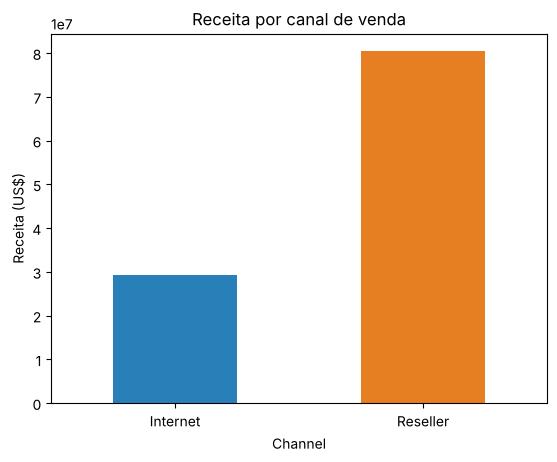

In [5]:
receita_canal = df.groupby("Channel")["Sales Amount"].sum()
print(receita_canal)

receita_canal.plot(kind="bar", color=["#2980b9", "#e67e22"])
plt.title("Receita por canal de venda")
plt.ylabel("Receita (US$)")
plt.xticks(rotation=0)
plt.show()

### Receita por categoria de produto

Category
Accessories    1,272,058
Bikes         94,620,526
Clothing       2,117,613
Components    11,799,077
Name: Sales Amount, dtype: float64


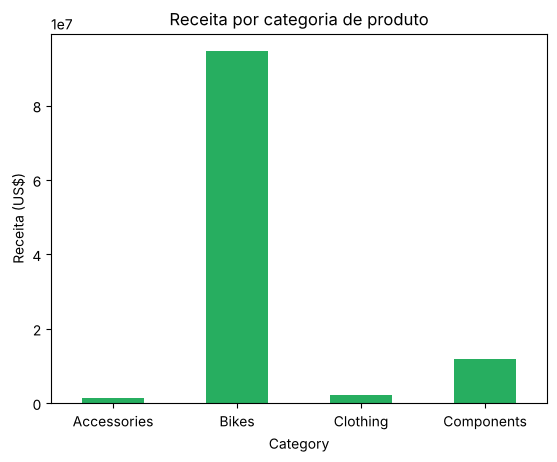

In [6]:
receita_categoria = df.groupby("Category")["Sales Amount"].sum()
print(receita_categoria)

receita_categoria.plot(kind="bar", color="#27ae60")
plt.title("Receita por categoria de produto")
plt.ylabel("Receita (US$)")
plt.xticks(rotation=0)
plt.show()

### Receita por ano

Ano
2017   11,928,556
2018   30,516,892
2019   42,895,110
2020   24,468,717
Name: Sales Amount, dtype: float64


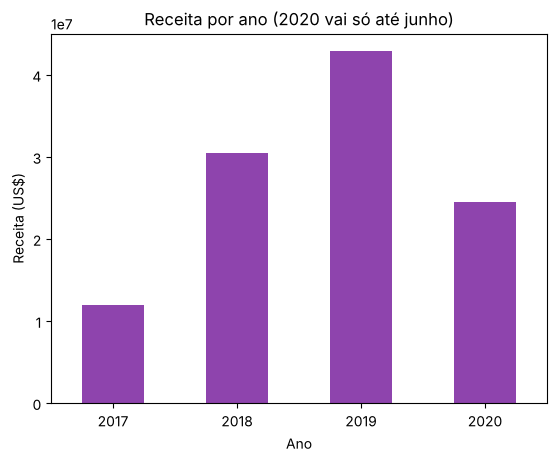

In [7]:
receita_ano = df.groupby("Ano")["Sales Amount"].sum()
print(receita_ano)

receita_ano.plot(kind="bar", color="#8e44ad")
plt.title("Receita por ano (2020 vai só até junho)")
plt.ylabel("Receita (US$)")
plt.xticks(rotation=0)
plt.show()

## 5. Clientes perdidos

Vendas para revendedores não têm cliente individual. Por isso, para analisar clientes, vamos usar só o canal **Internet** (vendas online).

Para cada cliente vamos descobrir: quantos pedidos fez e quando foi a última compra.

In [8]:
online = df[df["Channel"] == "Internet"]

# Uma linha por cliente
clientes_online = online.groupby("CustomerKey").agg({
    "Sales Order": "nunique",   # quantidade de pedidos
    "Data": "max",              # data da última compra
    "Country": "first",         # país
})
clientes_online.columns = ["pedidos", "ultima_compra", "pais"]

# Quantos dias faz que o cliente não compra?
ultima_data_da_base = online["Data"].max()
clientes_online["dias_sem_comprar"] = (ultima_data_da_base - clientes_online["ultima_compra"]).dt.days

# Perdido = mais de 180 dias sem comprar
clientes_online["perdido"] = clientes_online["dias_sem_comprar"] > 180

total = len(clientes_online)
perdidos = clientes_online["perdido"].sum()
print("Total de clientes online:", total)
print("Clientes perdidos:", perdidos)
print("Porcentagem de perdidos:", round(perdidos / total * 100, 1), "%")

clientes_online.head()

Total de clientes online: 18484
Clientes perdidos: 7871
Porcentagem de perdidos: 42.6 %


,pedidos,ultima_compra,pais,dias_sem_comprar,perdido
CustomerKey,,,,,
11000,3,2019-10-04,Australia,255,True
11001,3,2020-05-12,Australia,34,False
11002,3,2019-07-27,Australia,324,True
11003,3,2019-10-11,Australia,248,True
11004,3,2019-10-02,Australia,257,True


### Fator 1: quantas vezes o cliente comprou?

tipo
Comprou 1 vez      48
Comprou 2+ vezes   33
Name: perdido, dtype: float64


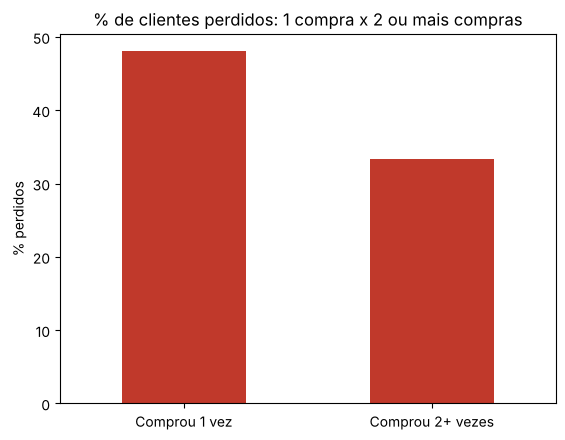

In [9]:
# Separar quem comprou 1 vez de quem comprou 2 ou mais
clientes_online["tipo"] = "Comprou 2+ vezes"
clientes_online.loc[clientes_online["pedidos"] == 1, "tipo"] = "Comprou 1 vez"

perda_por_tipo = clientes_online.groupby("tipo")["perdido"].mean() * 100
print(perda_por_tipo.round(1))

perda_por_tipo.plot(kind="bar", color="#c0392b")
plt.title("% de clientes perdidos: 1 compra x 2 ou mais compras")
plt.ylabel("% perdidos")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

### Fator 2: país do cliente

pais
United States    46
France           44
Germany          42
United Kingdom   40
Canada           39
Australia        37
Name: perdido, dtype: float64


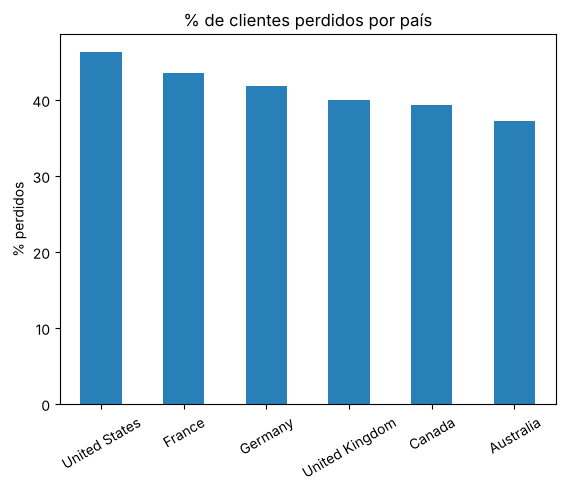

In [10]:
perda_por_pais = clientes_online.groupby("pais")["perdido"].mean() * 100
perda_por_pais = perda_por_pais.sort_values(ascending=False)
print(perda_por_pais.round(1))

perda_por_pais.plot(kind="bar", color="#2980b9")
plt.title("% de clientes perdidos por país")
plt.ylabel("% perdidos")
plt.xlabel("")
plt.xticks(rotation=30)
plt.show()

## 6. Conclusões

- **Canais:** os revendedores vendem mais (cerca de US$ 80,5 milhões) do que a loja online (cerca de US$ 29,4 milhões).
- **Produtos:** *Bikes* representam cerca de 86% de toda a receita.
- **Evolução:** a receita cresceu de 2017 a 2019 (2020 só vai até junho).
- **Clientes perdidos:** 42,6% dos clientes online (7.871 de 18.484) estão há mais de 180 dias sem comprar.
- **Recompra:** quem comprou só uma vez tem muito mais chance de ser perdido (48%) do que quem comprou 2 ou mais vezes (33%).
- **País:** os Estados Unidos têm a maior taxa de perda (46%) e a Austrália a menor (37%).

**Sugestão para a empresa:** incentivar a segunda compra (por exemplo, com cupom ou e-mail depois da primeira compra), já que é o fator mais ligado à perda de clientes.

**Limitações:** "cliente perdido" é uma aproximação (180 dias sem comprar), e os fatores analisados estão *associados* à perda, mas não provam a causa.